# Detecção de Fraude em Cartão de Crédito

**Autor:** Breno Lins Rocha · Desafio DIO · Bradesco: Agentes de IA do Zero à Prática

Neste notebook eu treino e comparo modelos para detectar fraudes em transações reais de cartão de crédito.
A base tem **284.807 transações** e só **0,17%** são fraude. Por isso a acurácia engana: um modelo que diz
"não é fraude" para tudo acerta 99,8% e não pega nenhuma fraude.

**Métrica principal:** recall da classe fraude (quantas fraudes o modelo encontra), sempre olhando junto a
precisão (quantos alertas são fraude de verdade) e o F1.

**Roteiro:**
1. Explorar os dados
2. Mostrar por que a acurácia engana
3. Preparar os dados (novas variáveis, padronização, divisão estratificada)
4. Treinar Regressão Logística, Random Forest e XGBoost com peso de classes
5. Comparar pelas métricas certas e pelas curvas ROC e Precisão-Recall
6. Ajustar o limiar de decisão
7. Testar undersampling e oversampling
8. Explicar o modelo com importância das variáveis e SHAP

## 0. Configuração

In [1]:
# No Google Colab, xgboost e shap já vêm instalados.
# Se rodar localmente e faltar algum, descomente a linha abaixo:
# %pip install -q xgboost shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.utils import resample
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve,
)
from xgboost import XGBClassifier
import shap

SEED = 42
np.random.seed(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.figsize"] = (8, 5)

C:\Users\Breno\AppData\Local\Temp\claude\c--Users-Breno-Desktop-Projects-Bradesco--AGENTES-DE-IA-desafio-2\291fc25b-76f0-4d6c-82df-cee7a94370b5\scratchpad\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Explorar os dados

O dataset é carregado direto pelo link, sem ficar salvo no repositório.
As colunas `V1` a `V28` foram transformadas por PCA para proteger a privacidade dos clientes.
`Time` é o tempo em segundos desde a primeira transação, `Amount` é o valor e `Class` é o alvo (1 = fraude).

In [2]:
# Link do dataset (o mesmo da Aula 1). Se o link da aula for outro, troque aqui.
DATASET_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(DATASET_URL)
print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")
df.head()

Linhas: 284,807 | Colunas: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
print("Valores ausentes no total:", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
df[["Time", "Amount", "Class"]].describe()

Valores ausentes no total: 0


Linhas duplicadas: 1081


,Time,Amount,Class
count,"284,807.0000","284,807.0000","284,807.0000"
mean,"94,813.8596",88.3496,0.0017
std,"47,488.1460",250.1201,0.0415
min,0.0000,0.0000,0.0000
25%,"54,201.5000",5.6000,0.0000
50%,"84,692.0000",22.0000,0.0000
75%,"139,320.5000",77.1650,0.0000
max,"172,792.0000","25,691.1600",1.0000


,Transações,%
Class,,
Normal,284315,99.8273
Fraude,492,0.1727


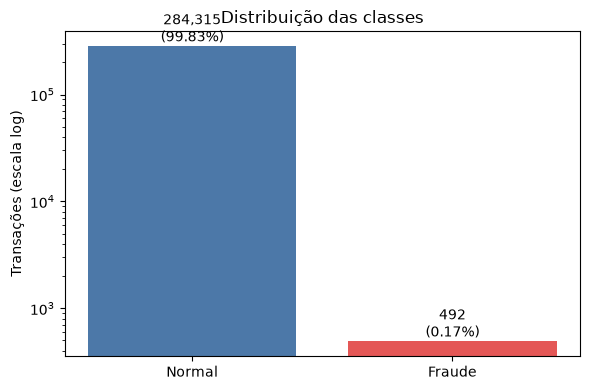

In [5]:
contagem = df["Class"].value_counts().rename({0: "Normal", 1: "Fraude"})
proporcao = df["Class"].value_counts(normalize=True).rename({0: "Normal", 1: "Fraude"}) * 100

resumo = pd.DataFrame({"Transações": contagem, "%": proporcao})
display(resumo)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(resumo.index, resumo["Transações"], color=["#4C78A8", "#E45756"])
ax.set_yscale("log")
ax.set_ylabel("Transações (escala log)")
ax.set_title("Distribuição das classes")
for i, (n, p) in enumerate(zip(resumo["Transações"], resumo["%"])):
    ax.text(i, n, f"{n:,}\n({p:.2f}%)", ha="center", va="bottom")
plt.tight_layout()
plt.show()

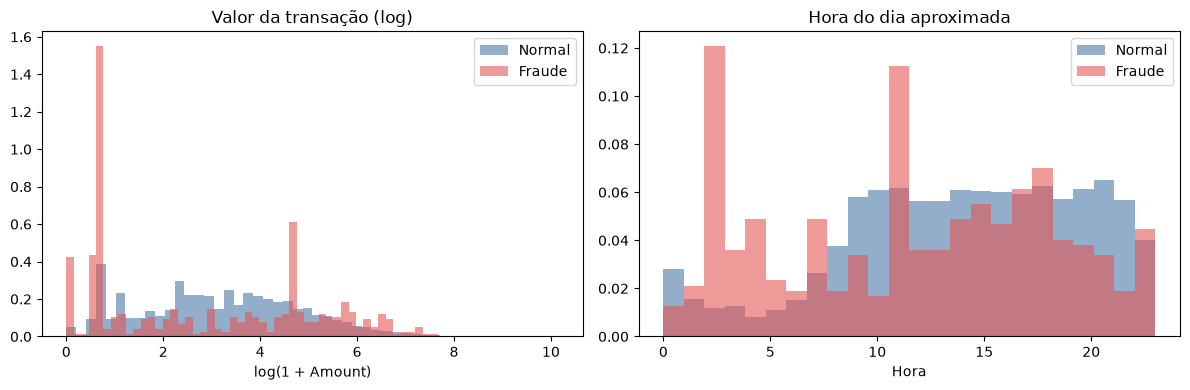

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for classe, cor, nome in [(0, "#4C78A8", "Normal"), (1, "#E45756", "Fraude")]:
    valores = df.loc[df["Class"] == classe, "Amount"]
    axes[0].hist(np.log1p(valores), bins=50, alpha=0.6, density=True, color=cor, label=nome)
    horas = (df.loc[df["Class"] == classe, "Time"] // 3600) % 24
    axes[1].hist(horas, bins=24, alpha=0.6, density=True, color=cor, label=nome)

axes[0].set_title("Valor da transação (log)")
axes[0].set_xlabel("log(1 + Amount)")
axes[1].set_title("Hora do dia aproximada")
axes[1].set_xlabel("Hora")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Leitura:** as fraudes se concentram em horários de madrugada com mais intensidade, relativamente,
do que as transações normais. Isso motivou a variável `Hora` criada na preparação.

## 2. Por que a acurácia engana

Um "modelo" que sempre responde **não é fraude** serve de prova.

In [7]:
X_tmp = df.drop(columns="Class")
y_tmp = df["Class"]
burro = DummyClassifier(strategy="most_frequent").fit(X_tmp, y_tmp)
pred_burro = burro.predict(X_tmp)

print(f"Acurácia do modelo que nunca acusa fraude: {accuracy_score(y_tmp, pred_burro):.4%}")
print(f"Recall da fraude (fraudes encontradas):     {recall_score(y_tmp, pred_burro):.4%}")
del X_tmp, y_tmp

Acurácia do modelo que nunca acusa fraude: 99.8273%
Recall da fraude (fraudes encontradas):     0.0000%


Acurácia de 99,8% e **zero fraudes encontradas**. Por isso, daqui em diante:

- **Recall (fraude):** de todas as fraudes reais, quantas o modelo pegou. É a métrica principal.
- **Precisão (fraude):** de todos os alertas, quantos eram fraude. Precisão baixa = muitos clientes bloqueados à toa.
- **F1:** equilíbrio entre os dois.
- **AUC-PR:** área sob a curva Precisão-Recall, melhor que a AUC-ROC quando a classe positiva é rara.

## 3. Preparar os dados

1. **Novas variáveis:** `Amount_log` (log do valor, reduz o efeito de valores muito altos) e `Hora` (hora do dia aproximada, vinda de `Time`).
2. **Divisão estratificada** em treino (60%), validação (20%) e teste (20%), mantendo 0,17% de fraude em todas.
   A validação serve para escolher o limiar sem "espiar" o teste.
3. **StandardScaler** ajustado só no treino, para não vazar informação do teste.

In [8]:
dados = df.copy()
dados["Amount_log"] = np.log1p(dados["Amount"])
dados["Hora"] = (dados["Time"] // 3600) % 24
dados = dados.drop(columns=["Time", "Amount"])

X = dados.drop(columns="Class")
y = dados["Class"]

# 80% treino+validação, 20% teste
X_trval, X_test, y_trval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
# dos 80%, 25% vira validação -> 60% / 20% / 20%
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED
)

for nome, alvo in [("Treino", y_train), ("Validação", y_val), ("Teste", y_test)]:
    print(f"{nome:10s} {len(alvo):>7,} linhas | fraudes: {alvo.sum():>4} ({alvo.mean():.4%})")

Treino     170,883 linhas | fraudes:  295 (0.1726%)
Validação   56,962 linhas | fraudes:   99 (0.1738%)
Teste       56,962 linhas | fraudes:   98 (0.1720%)


In [9]:
scaler = StandardScaler()
colunas = X.columns

X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=colunas, index=X_train.index)
X_val_s = pd.DataFrame(scaler.transform(X_val), columns=colunas, index=X_val.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=colunas, index=X_test.index)

X_train_s.describe().loc[["mean", "std"]].round(2)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount_log,Hora
mean,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,-0.0000,0.0000,-0.0000,0.0000,0.0000,-0.0000,-0.0000
std,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


## 4. Treinar os modelos

Todos usam **peso de classes**, que faz o erro em uma fraude "custar" mais que o erro em uma transação normal:

- **Regressão Logística** (baseline): `class_weight="balanced"`
- **Random Forest**: `class_weight="balanced_subsample"`
- **XGBoost**: `scale_pos_weight` = normais / fraudes do treino

In [10]:
def avaliar(nome, y_true, proba, limiar=0.5):
    """Calcula as métricas da classe fraude para um limiar de decisão."""
    pred = (proba >= limiar).astype(int)
    return {
        "Modelo": nome,
        "Limiar": limiar,
        "Recall": recall_score(y_true, pred, zero_division=0),
        "Precisão": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_true, proba),
        "AUC-PR": average_precision_score(y_true, proba),
        "Fraudes pegas": int(((pred == 1) & (y_true == 1)).sum()),
        "Fraudes perdidas": int(((pred == 0) & (y_true == 1)).sum()),
        "Alarmes falsos": int(((pred == 1) & (y_true == 0)).sum()),
    }

In [11]:
peso_fraude = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight do XGBoost: {peso_fraude:.1f}")

modelos = {
    "Regressão Logística": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
        n_jobs=-1, random_state=SEED
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=peso_fraude,
        eval_metric="aucpr", n_jobs=-1, random_state=SEED
    ),
}

proba_val, proba_test = {}, {}
for nome, modelo in modelos.items():
    modelo.fit(X_train_s, y_train)
    proba_val[nome] = modelo.predict_proba(X_val_s)[:, 1]
    proba_test[nome] = modelo.predict_proba(X_test_s)[:, 1]
    print(f"{nome} treinado")

scale_pos_weight do XGBoost: 578.3


Regressão Logística treinado


Random Forest treinado


XGBoost treinado


## 5. Comparar os modelos (limiar padrão de 0,5, no conjunto de teste)

In [12]:
tabela_padrao = pd.DataFrame([avaliar(n, y_test, p) for n, p in proba_test.items()]).set_index("Modelo")
tabela_padrao

,Limiar,Recall,Precisão,F1,AUC-ROC,AUC-PR,Fraudes pegas,Fraudes perdidas,Alarmes falsos
Modelo,,,,,,,,,
Regressão Logística,0.5000,0.8980,0.0558,0.1050,0.9722,0.7095,88,10,1490
Random Forest,0.5000,0.7653,0.9494,0.8475,0.9615,0.8601,75,23,4
XGBoost,0.5000,0.8469,0.8925,0.8691,0.9752,0.8734,83,15,10


In [13]:
for nome, proba in proba_test.items():
    print(f"===== {nome} =====")
    print(classification_report(y_test, (proba >= 0.5).astype(int),
                                target_names=["Normal", "Fraude"], digits=4))

===== Regressão Logística =====
              precision    recall  f1-score   support

      Normal     0.9998    0.9738    0.9866     56864
      Fraude     0.0558    0.8980    0.1050        98

    accuracy                         0.9737     56962
   macro avg     0.5278    0.9359    0.5458     56962
weighted avg     0.9982    0.9737    0.9851     56962

===== Random Forest =====
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56864
      Fraude     0.9494    0.7653    0.8475        98

    accuracy                         0.9995     56962
   macro avg     0.9745    0.8826    0.9236     56962
weighted avg     0.9995    0.9995    0.9995     56962

===== XGBoost =====


              precision    recall  f1-score   support

      Normal     0.9997    0.9998    0.9998     56864
      Fraude     0.8925    0.8469    0.8691        98

    accuracy                         0.9996     56962
   macro avg     0.9461    0.9234    0.9344     56962
weighted avg     0.9996    0.9996    0.9996     56962



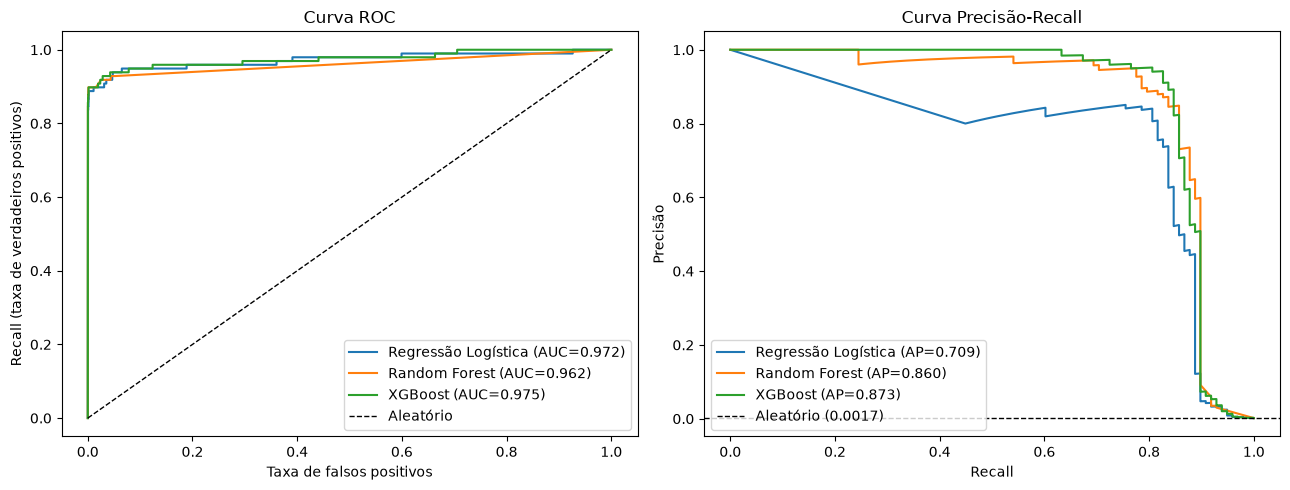

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for nome, proba in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y_test, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{nome} (AP={average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Aleatório")
axes[0].set(title="Curva ROC", xlabel="Taxa de falsos positivos", ylabel="Recall (taxa de verdadeiros positivos)")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Aleatório ({y_test.mean():.4f})")
axes[1].set(title="Curva Precisão-Recall", xlabel="Recall", ylabel="Precisão")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left")
plt.tight_layout()
plt.show()

**Leitura:** a curva ROC fica perto do canto superior esquerdo para todos os modelos e parece ótima,
porque o número enorme de transações normais deixa a taxa de falsos positivos pequena.
A curva Precisão-Recall é mais honesta: mostra quanto de precisão se perde para pegar mais fraudes.

## 6. Ajustar o limiar de decisão

O limiar 0,5 é só um padrão. Baixar o limiar pega mais fraudes (mais recall) e gera mais alarmes falsos
(menos precisão). Minha regra de negócio:

> **Escolher, na validação, o limiar com a maior precisão possível desde que o recall seja de pelo menos 85%.**
> Se nenhum limiar chegar a 85%, uso o limiar de maior F1.

O limiar é escolhido na **validação** e só depois aplicado no **teste**, para o resultado não ficar otimista.

In [15]:
RECALL_MINIMO = 0.85


def escolher_limiar(y_true, proba, recall_minimo=RECALL_MINIMO):
    prec, rec, limiares = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]  # o último ponto não tem limiar
    ok = rec >= recall_minimo
    if ok.any():
        idx = np.argmax(np.where(ok, prec, -1))
    else:
        f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
        idx = np.argmax(f1)
    return float(limiares[idx])


limiares = {nome: escolher_limiar(y_val, proba_val[nome]) for nome in modelos}
pd.Series(limiares, name="Limiar escolhido na validação").round(4).to_frame()

,Limiar escolhido na validação
Regressão Logística,0.7505
Random Forest,0.0150
XGBoost,0.0028


In [16]:
tabela_ajustada = pd.DataFrame(
    [avaliar(n, y_test, proba_test[n], limiares[n]) for n in modelos]
).set_index("Modelo")

comparacao = pd.concat(
    {"Limiar 0,5": tabela_padrao[["Recall", "Precisão", "F1", "Alarmes falsos"]],
     "Limiar ajustado": tabela_ajustada[["Limiar", "Recall", "Precisão", "F1", "Alarmes falsos"]]},
    axis=1,
)
comparacao

Limiar 0,5                                Limiar ajustado  \
                        Recall Precisão     F1 Alarmes falsos          Limiar   
Modelo                                                                          
Regressão Logística     0.8980   0.0558 0.1050           1490          0.7505   
Random Forest           0.7653   0.9494 0.8475              4          0.0150   
XGBoost                 0.8469   0.8925 0.8691             10          0.0028   

                                                           
                    Recall Precisão     F1 Alarmes falsos  
Modelo                                                     
Regressão Logística 0.8980   0.1186 0.2095            654  
Random Forest       0.8980   0.2521 0.3937            261  
XGBoost             0.8980   0.3014 0.4513            204

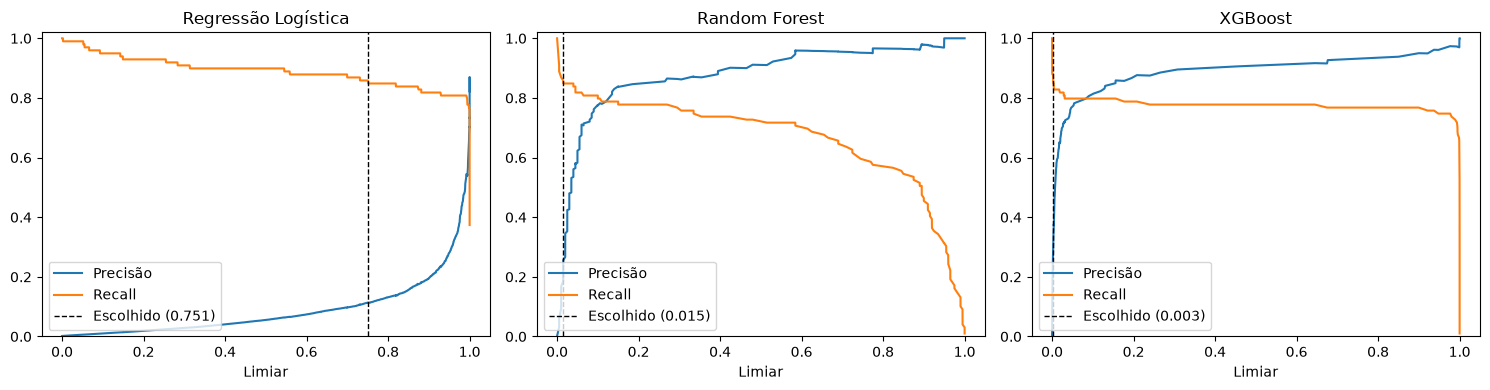

In [17]:
fig, axes = plt.subplots(1, len(modelos), figsize=(5 * len(modelos), 4))
for ax, nome in zip(axes, modelos):
    prec, rec, lim = precision_recall_curve(y_val, proba_val[nome])
    ax.plot(lim, prec[:-1], label="Precisão")
    ax.plot(lim, rec[:-1], label="Recall")
    ax.axvline(limiares[nome], color="k", ls="--", lw=1, label=f"Escolhido ({limiares[nome]:.3f})")
    ax.set(title=nome, xlabel="Limiar", ylim=(0, 1.02))
    ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

Modelo escolhido: XGBoost | limiar 0.0028


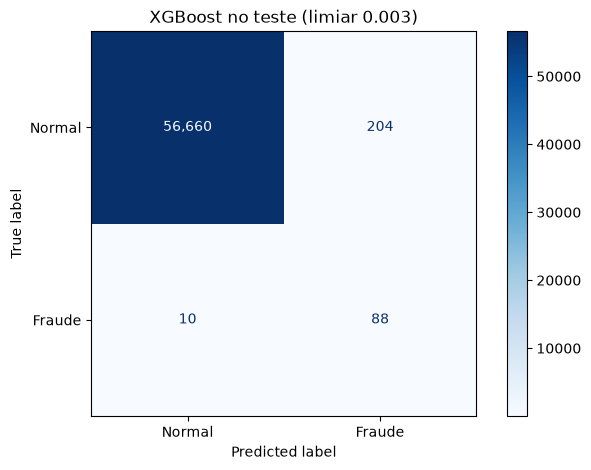

In [18]:
melhor = tabela_ajustada.sort_values(["Recall", "Precisão"], ascending=False).index[0]
print("Modelo escolhido:", melhor, f"| limiar {limiares[melhor]:.4f}")

pred_final = (proba_test[melhor] >= limiares[melhor]).astype(int)
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_final), display_labels=["Normal", "Fraude"]
).plot(cmap="Blues", values_format=",")
plt.title(f"{melhor} no teste (limiar {limiares[melhor]:.3f})")
plt.show()

## 7. Undersampling e oversampling

Outra forma de lidar com o desbalanceamento é mudar o próprio treino, em vez de usar peso de classes:

- **Undersampling:** joga fora transações normais até ficar 1 normal para cada fraude.
- **Oversampling:** repete fraudes (sorteio com reposição) até igualar o número de normais.

A reamostragem é feita **só no treino**. Validação e teste continuam com a proporção real.
Seguindo a regra da Expert ("teste"), comparo os três jeitos na Regressão Logística e no XGBoost.

In [19]:
treino = X_train_s.assign(Class=y_train.values)
normais = treino[treino["Class"] == 0]
fraudes = treino[treino["Class"] == 1]

under = pd.concat([resample(normais, n_samples=len(fraudes), replace=False, random_state=SEED), fraudes])
over = pd.concat([normais, resample(fraudes, n_samples=len(normais), replace=True, random_state=SEED)])

bases = {"Peso de classes": treino, "Undersampling": under, "Oversampling": over}
for nome, base in bases.items():
    print(f"{nome:16s} {len(base):>7,} linhas | fraudes: {base['Class'].mean():.2%}")

Peso de classes  170,883 linhas | fraudes: 0.17%
Undersampling        590 linhas | fraudes: 50.00%
Oversampling     341,176 linhas | fraudes: 50.00%


In [20]:
def novo_modelo(tipo, estrategia):
    usa_peso = estrategia == "Peso de classes"
    if tipo == "Regressão Logística":
        return LogisticRegression(class_weight="balanced" if usa_peso else None,
                                  max_iter=1000, random_state=SEED)
    return XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                         colsample_bytree=0.8, scale_pos_weight=peso_fraude if usa_peso else 1,
                         eval_metric="aucpr", n_jobs=-1, random_state=SEED)


linhas = []
for tipo in ["Regressão Logística", "XGBoost"]:
    for estrategia, base in bases.items():
        m = novo_modelo(tipo, estrategia)
        m.fit(base.drop(columns="Class"), base["Class"])
        pv = m.predict_proba(X_val_s)[:, 1]
        pt = m.predict_proba(X_test_s)[:, 1]
        lim = escolher_limiar(y_val, pv)
        r = avaliar(f"{tipo} | {estrategia}", y_test, pt, lim)
        linhas.append(r)

tabela_sampling = pd.DataFrame(linhas).set_index("Modelo")
tabela_sampling[["Limiar", "Recall", "Precisão", "F1", "AUC-PR", "Alarmes falsos"]]

,Limiar,Recall,Precisão,F1,AUC-PR,Alarmes falsos
Modelo,,,,,,
Regressão Logística | Peso de classes,0.7505,0.8980,0.1186,0.2095,0.7095,654
Regressão Logística | Undersampling,0.9364,0.8878,0.1105,0.1966,0.4158,700
Regressão Logística | Oversampling,0.7779,0.8878,0.1285,0.2245,0.7108,590
XGBoost | Peso de classes,0.0028,0.8980,0.3014,0.4513,0.8734,204
XGBoost | Undersampling,0.8401,0.8980,0.0761,0.1404,0.5909,1068
XGBoost | Oversampling,0.0049,0.8980,0.3607,0.5146,0.8782,156


**Leitura:** o undersampling treina com pouquíssimos exemplos normais, então tende a gerar muitos
alarmes falsos. O oversampling e o peso de classes usam todos os dados e costumam ficar parecidos.
Com o limiar ajustado na validação, as três estratégias ficam comparáveis no mesmo recall mínimo,
e a diferença aparece na precisão.

## 8. Explicar o modelo

### 8.1 Importância das variáveis

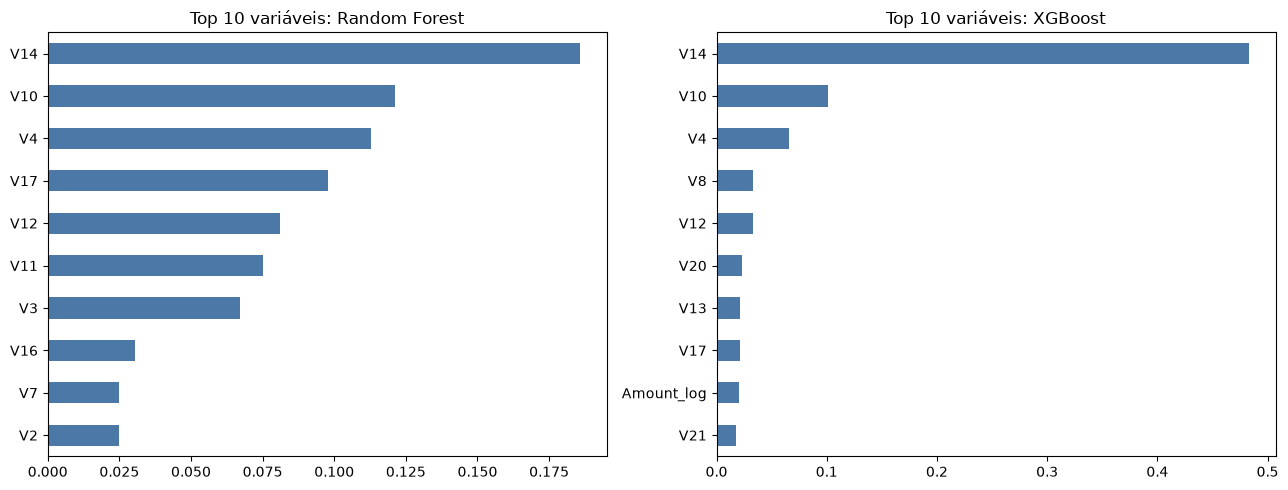

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, nome in zip(axes, ["Random Forest", "XGBoost"]):
    imp = pd.Series(modelos[nome].feature_importances_, index=colunas).sort_values().tail(10)
    imp.plot.barh(ax=ax, color="#4C78A8")
    ax.set_title(f"Top 10 variáveis: {nome}")
plt.tight_layout()
plt.show()

### 8.2 SHAP

A importância acima diz **quais** variáveis o modelo mais usa, mas não **para que lado** elas empurram.
O SHAP mostra, para cada transação, quanto cada variável aumentou ou diminuiu a chance de fraude.

C:\Users\Breno\AppData\Local\Temp\ipykernel_11884\2663010374.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, amostra, max_display=12, show=False)


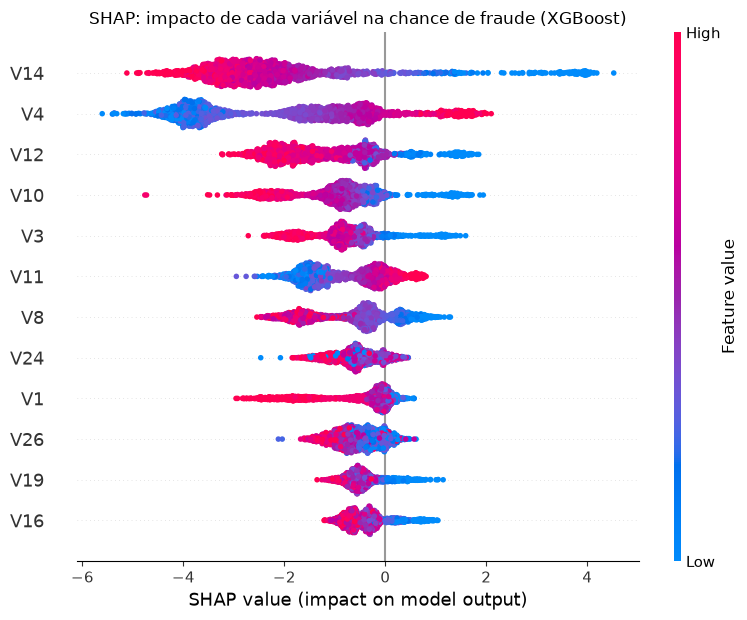

In [22]:
explainer = shap.TreeExplainer(modelos["XGBoost"])

# amostra do teste com todas as fraudes + 2.000 normais (para ficar rápido)
idx_fraude = y_test[y_test == 1].index
idx_normal = y_test[y_test == 0].sample(2000, random_state=SEED).index
amostra = X_test_s.loc[idx_fraude.union(idx_normal)]

shap_values = explainer(amostra)
shap.summary_plot(shap_values, amostra, max_display=12, show=False)
plt.title("SHAP: impacto de cada variável na chance de fraude (XGBoost)")
plt.tight_layout()
plt.show()

Transação 42769: probabilidade de fraude = 1.0000


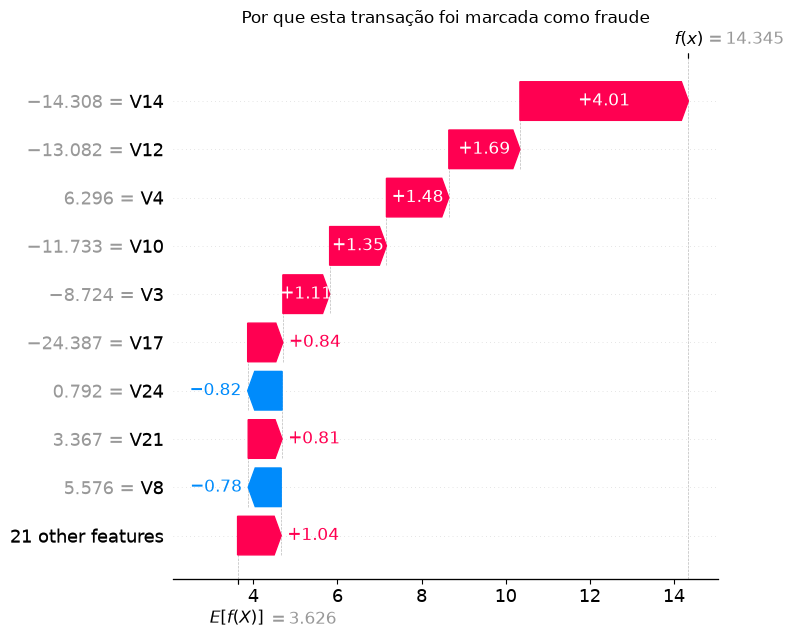

In [23]:
# Uma fraude real que o XGBoost marcou corretamente
proba_xgb = pd.Series(proba_test["XGBoost"], index=X_test_s.index)
pegas = proba_xgb[(y_test == 1) & (proba_xgb >= limiares["XGBoost"])]
exemplo = pegas.idxmax()
print(f"Transação {exemplo}: probabilidade de fraude = {proba_xgb[exemplo]:.4f}")

pos = amostra.index.get_loc(exemplo)
shap.plots.waterfall(shap_values[pos], max_display=10, show=False)
plt.title("Por que esta transação foi marcada como fraude")
plt.tight_layout()
plt.show()

**Como ler:** no gráfico de resumo, cada ponto é uma transação. Pontos à direita aumentaram a chance de fraude;
a cor mostra se o valor da variável era alto (vermelho) ou baixo (azul). Por exemplo, valores **baixos** de
`V14`, `V12` e `V10` (pontos azuis à direita) costumam empurrar fortemente para fraude.
No gráfico de cascata, dá para ver variável por variável o que levou **uma transação específica** a ser marcada.

## 9. Resumo final

In [24]:
resumo_final = pd.concat([
    tabela_ajustada[["Limiar", "Recall", "Precisão", "F1", "AUC-PR", "Fraudes pegas", "Fraudes perdidas", "Alarmes falsos"]],
    tabela_sampling[["Limiar", "Recall", "Precisão", "F1", "AUC-PR", "Fraudes pegas", "Fraudes perdidas", "Alarmes falsos"]],
])
resumo_final.sort_values("F1", ascending=False)

,Limiar,Recall,Precisão,F1,AUC-PR,Fraudes pegas,Fraudes perdidas,Alarmes falsos
Modelo,,,,,,,,
XGBoost | Oversampling,0.0049,0.8980,0.3607,0.5146,0.8782,88,10,156
XGBoost,0.0028,0.8980,0.3014,0.4513,0.8734,88,10,204
XGBoost | Peso de classes,0.0028,0.8980,0.3014,0.4513,0.8734,88,10,204
Random Forest,0.0150,0.8980,0.2521,0.3937,0.8601,88,10,261
Regressão Logística | Oversampling,0.7779,0.8878,0.1285,0.2245,0.7108,87,11,590
Regressão Logística,0.7505,0.8980,0.1186,0.2095,0.7095,88,10,654
Regressão Logística | Peso de classes,0.7505,0.8980,0.1186,0.2095,0.7095,88,10,654
Regressão Logística | Undersampling,0.9364,0.8878,0.1105,0.1966,0.4158,87,11,700
XGBoost | Undersampling,0.8401,0.8980,0.0761,0.1404,0.5909,88,10,1068


### Conclusões

- A acurácia não serve para este problema: o modelo que nunca acusa fraude tem 99,8% de acurácia e recall zero.
- Com peso de classes e limiar ajustado na validação, os modelos de árvore (Random Forest e XGBoost) encontram a
  grande maioria das fraudes com bem menos alarmes falsos que a Regressão Logística.
- Ajustar o limiar muda muito o resultado sem retreinar nada. A escolha final é uma decisão de negócio:
  quanto custa perder uma fraude contra quanto custa bloquear um cliente honesto.
- O SHAP mostrou que poucas variáveis do PCA (como `V14`, `V4`, `V12` e `V10`) concentram a maior parte da decisão.

> Os números exatos de cada modelo estão nas tabelas acima e no README do repositório.